# 02 — Multiple Linear Regression

> Predicting with several input features at once, by fitting a plane instead of a line.

The summary of this lesson is in [README.md](README.md). This notebook is the
full working: the reasoning, the code, and the results.

**Contents**

1. The problem
2. Intuition
3. The mathematics
4. The data
5. Modeling
6. Results and interpretation
7. References

## 1. The problem

Lesson 01 predicted a car's CO2 emissions from its engine size alone and reached
an R² of about 0.76. The quarter of the variation it could not explain was not
noise — it was the influence of everything else about the car that a single
feature has no way to express.

This lesson gives the model more to work with: engine size **and** cylinder
count **and** combined fuel consumption, all at once.

- **Inputs:** three numbers per car
- **Output:** CO2 emissions, in grams per kilometre
- **The question:** does knowing more about each car produce better predictions,
  and by how much?

## 2. Intuition

With one feature, the model was a line through a scatter of points on a flat
chart. With two features it becomes a **plane** hovering over a 3D cloud of
points. With three or more it becomes a *hyperplane*, which cannot be drawn but
behaves identically.

The fitting rule does not change. The model still chooses the surface that makes
the squared vertical distances to the data as small as possible. Only the number
of directions the surface is allowed to tilt in has changed — one slope per
feature instead of a single one.

Each slope answers a conditional question: *holding everything else fixed, how
much do emissions change per unit of this feature?* That conditional phrasing is
what makes multiple regression harder to interpret than simple regression, and
section 6 comes back to it.

## 3. The mathematics

**Model.** With $n$ features $x_1, \dots, x_n$:

$$
\hat{y} = b + w_1 x_1 + w_2 x_2 + \cdots + w_n x_n
$$

Or compactly, with $\mathbf{w}$ the vector of coefficients:

$$
\hat{y} = b + \mathbf{w}^{\top} \mathbf{x}
$$

Simple linear regression is this with $n = 1$, which is why the extension costs
almost nothing in code.

**Cost function.** Unchanged from lesson 01 — the residual sum of squares,
averaged over $m$ training cars:

$$
J(\mathbf{w}, b) = \frac{1}{m} \sum_{i=1}^{m} \left( \hat{y}^{(i)} - y^{(i)} \right)^2
$$

**Finding the parameters — Ordinary Least Squares.** $J$ is still quadratic in
the parameters, so it still has one minimum and no local traps. Setting the
partial derivatives with respect to every $w_j$ and $b$ to zero gives a linear
system that can be solved in one step. That is what scikit-learn's
`LinearRegression` does, and it is why adding features does not make fitting
slower to converge — there is nothing to converge to.

The alternative, used when the closed form is too expensive or does not exist,
is an iterative optimiser such as gradient descent. For a dataset this size the
direct solution is the obvious choice.

## 4. The data

The same dataset as lesson 01: fuel consumption ratings and CO2 emissions for
new light duty vehicles sold in Canada in 2014, published as open data by the
Government of Canada.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")

# Fixed seed so the train/test split is identical every run. Without this, the
# coefficients and scores reported below change each time the notebook executes.
RANDOM_SEED = 42

In [2]:
df = pd.read_csv("data/FuelConsumption.csv")

# take a look at the dataset
df.head()

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


In [3]:
# summarize the data
df.describe()

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
count,1067.0,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000,1067.000000
mean,2014.0,3.346298,5.794752,13.296532,9.474602,11.580881,26.441425,256.228679
std,0.0,1.415895,1.797447,4.101253,2.794510,3.485595,7.468702,63.372304
min,2014.0,1.000000,3.000000,4.600000,4.900000,4.700000,11.000000,108.000000
25%,2014.0,2.000000,4.000000,10.250000,7.500000,9.000000,21.000000,207.000000
50%,2014.0,3.400000,6.000000,12.600000,8.800000,10.900000,26.000000,251.000000
75%,2014.0,4.300000,8.000000,15.550000,10.850000,13.350000,31.000000,294.000000
max,2014.0,8.400000,12.000000,30.200000,20.500000,25.800000,60.000000,488.000000


This time I keep more of the numeric columns, because the point of the lesson is
to use several of them at once.

In [4]:
cdf = df[
    [
        "ENGINESIZE",
        "CYLINDERS",
        "FUELCONSUMPTION_CITY",
        "FUELCONSUMPTION_HWY",
        "FUELCONSUMPTION_COMB",
        "CO2EMISSIONS",
    ]
]
cdf.head(9)

,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,CO2EMISSIONS
0,2.0,4,9.9,6.7,8.5,196
1,2.4,4,11.2,7.7,9.6,221
2,1.5,4,6.0,5.8,5.9,136
3,3.5,6,12.7,9.1,11.1,255
4,3.5,6,12.1,8.7,10.6,244
5,3.5,6,11.9,7.7,10.0,230
6,3.5,6,11.8,8.1,10.1,232
7,3.7,6,12.8,9.0,11.1,255
8,3.7,6,13.4,9.5,11.6,267


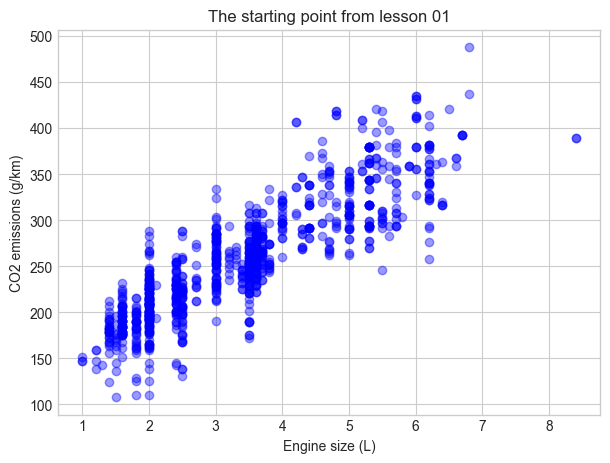

In [5]:
plt.figure(figsize=(7, 5))
plt.scatter(cdf.ENGINESIZE, cdf.CO2EMISSIONS, color="blue", alpha=0.4)
plt.xlabel("Engine size (L)")
plt.ylabel("CO2 emissions (g/km)")
plt.title("The starting point from lesson 01")
plt.show()

This is where lesson 01 finished: a clear upward trend, and a wide vertical band
of cars at every engine size that a single feature cannot separate. The features
added below are an attempt to explain that band.

Before using them together, it is worth knowing how related they already are to
each other.

In [6]:
cdf.corr()

,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,CO2EMISSIONS
ENGINESIZE,1.000000,0.934011,0.832225,0.778746,0.819482,0.874154
CYLINDERS,0.934011,1.000000,0.796473,0.724594,0.776788,0.849685
FUELCONSUMPTION_CITY,0.832225,0.796473,1.000000,0.965718,0.995542,0.898039
FUELCONSUMPTION_HWY,0.778746,0.724594,0.965718,1.000000,0.985804,0.861748
FUELCONSUMPTION_COMB,0.819482,0.776788,0.995542,0.985804,1.000000,0.892129
CO2EMISSIONS,0.874154,0.849685,0.898039,0.861748,0.892129,1.000000


Engine size, cylinders and the three fuel consumption columns are all strongly
correlated with one another. That is expected, since they all describe roughly
the same underlying thing: how much engine the car has.

This matters for interpretation. When inputs move together, the fitted
coefficients split the shared effect between them in a way that is not stable —
small changes in the data can move one coefficient up and another down while the
predictions stay the same. The model can still predict well; it is the
*individual* coefficients that become unreliable. This is multicollinearity, and
it is why section 6 reads the coefficients cautiously.

### Creating train and test datasets

Exactly as in lesson 01: fit on one portion of the rows, measure on another the
model has never seen. Scoring a model on the rows it learned from measures
memory, not prediction.

In [7]:
# Going toward the common approach of 80% / 20% (80 for training, 20 for testing)
rng = np.random.default_rng(RANDOM_SEED)
msk = rng.random(len(cdf)) < 0.8

train = cdf[msk]
test = cdf[~msk]

print(f"training rows: {len(train)}")
print(f"test rows:     {len(test)}")

training rows: 859
test rows:     208


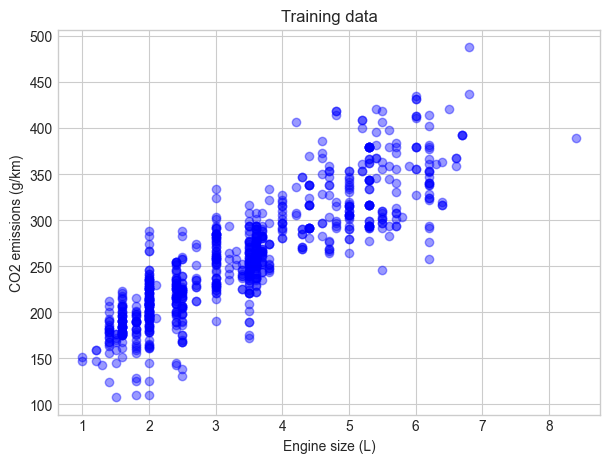

In [8]:
plt.figure(figsize=(7, 5))
plt.scatter(train.ENGINESIZE, train.CO2EMISSIONS, color="blue", alpha=0.4)
plt.xlabel("Engine size (L)")
plt.ylabel("CO2 emissions (g/km)")
plt.title("Training data")
plt.show()

## 5. Modeling

In reality many variables affect CO2 emissions. When more than one independent
variable goes into the model, the method is called multiple linear regression —
and as section 3 showed, it is the same estimator with a wider input.

I start with engine size, cylinders, and combined fuel consumption.

In [9]:
from sklearn import linear_model

reg = linear_model.LinearRegression()

# compared with the single one, we use multiple independent variables (Xs)
# instead of one, and here we use 3 of them
train_x = train[["ENGINESIZE", "CYLINDERS", "FUELCONSUMPTION_COMB"]].to_numpy()
train_y = train["CO2EMISSIONS"].to_numpy()

reg.fit(train_x, train_y)

print("Coefficients: ", reg.coef_)
print("Intercept:    ", reg.intercept_)

Coefficients:  [10.38961305  7.55455195  9.9416667 ]
Intercept:     63.022679517376815


Three coefficients now, one per feature, in the order they were passed: engine
size, cylinders, combined fuel consumption. Together with the intercept they
define a hyperplane in four dimensions.

Two of those dimensions can be drawn. Below is the fitted surface over engine
size and cylinders, with fuel consumption held at its average value — a slice
through the model rather than the whole of it.

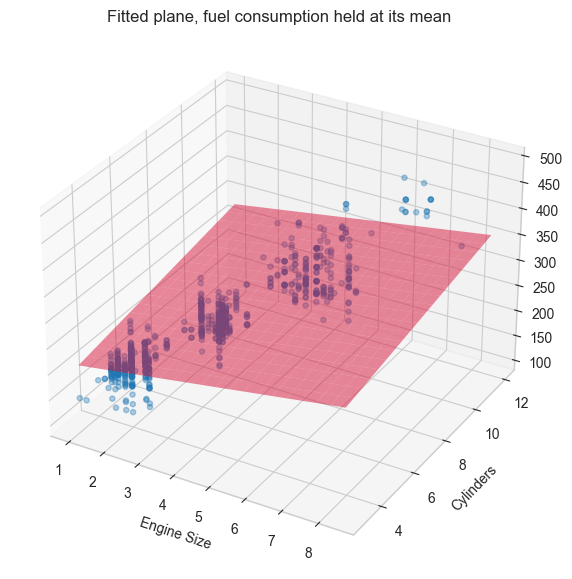

In [10]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(train.ENGINESIZE, train.CYLINDERS, train.CO2EMISSIONS, alpha=0.35, s=14)

x = np.linspace(train.ENGINESIZE.min(), train.ENGINESIZE.max(), 20)
y = np.linspace(train.CYLINDERS.min(), train.CYLINDERS.max(), 20)

X, Y = np.meshgrid(x, y)

# The third feature has to be pinned somewhere to draw a surface in 3D, so it is
# held at its mean: this is one slice through the model, not the whole model.
fuel = train.FUELCONSUMPTION_COMB.mean()

Z = reg.intercept_ + reg.coef_[0] * X + reg.coef_[1] * Y + reg.coef_[2] * fuel

ax.plot_surface(X, Y, Z, alpha=0.5, color="crimson")

ax.set_xlabel("Engine Size")
ax.set_ylabel("Cylinders")
ax.set_zlabel("CO2 Emissions", labelpad=10)
ax.set_title("Fitted plane, fuel consumption held at its mean")

# Saved so README.md can show the result without anyone running this notebook.
fig.savefig("figures/result.png", dpi=150, bbox_inches="tight", pad_inches=0.4)
plt.show()

The surface tilts upward in both drawn directions, and the points sit above and
below it rather than on it — the same residual spread as lesson 01, now in three
dimensions.

Note what the plot cannot show: because fuel consumption is frozen at its
average, cars whose consumption is unusual for their engine size look badly
predicted here even when the full model handles them well. A 3D picture of a 4D
object is always a slice.

## 6. Results and interpretation

### Evaluation

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

test_x = test[["ENGINESIZE", "CYLINDERS", "FUELCONSUMPTION_COMB"]].to_numpy()
test_y = test["CO2EMISSIONS"].to_numpy()

y_hat = reg.predict(test_x)

print(f"Mean absolute error:             {mean_absolute_error(test_y, y_hat):.2f} g/km")
print(f"Residual sum of squares (MSE):   {mean_squared_error(test_y, y_hat):.2f}")
print(f"Root mean squared error (RMSE):  {np.sqrt(mean_squared_error(test_y, y_hat)):.2f} g/km")
print(f"R2-score:                        {r2_score(test_y, y_hat):.2f}")

Mean absolute error:             18.47 g/km
Residual sum of squares (MSE):   635.97
Root mean squared error (RMSE):  25.22 g/km
R2-score:                        0.84


`reg.score(test_x, test_y)` would return the same R² as the line above; both are
computed on the test set, which the model has never seen.

**Explained variance.** R² compares the variance left in the residuals against
the variance of the target itself:

$$
R^2(y, \hat{y}) = 1 - \frac{\operatorname{Var}\{\, y - \hat{y} \,\}}{\operatorname{Var}\{\, y \,\}}
$$

1.0 is a perfect fit; 0 means the model does no better than always predicting the
mean; negative values mean it does worse than that.

### A second set of features

The combined fuel consumption figure is itself an average of the city and highway
numbers. Splitting it back into its two parts gives the model four features
instead of three, and slightly more detail to work with.

In [12]:
new_reg = linear_model.LinearRegression()

feature_names = [
    "ENGINESIZE",
    "CYLINDERS",
    "FUELCONSUMPTION_CITY",
    "FUELCONSUMPTION_HWY",
]

new_train_x = train[feature_names].to_numpy()
new_train_y = train["CO2EMISSIONS"].to_numpy()

new_reg.fit(new_train_x, new_train_y)

print("Coefficients: ", new_reg.coef_)
print("Intercept:    ", new_reg.intercept_)

Coefficients:  [10.39751404  7.53754071  5.50085324  4.4311708 ]
Intercept:     63.09499539529162


In [13]:
new_test_x = test[feature_names].to_numpy()
new_test_y = test["CO2EMISSIONS"].to_numpy()

new_y_hat = new_reg.predict(new_test_x)

print(f"Mean absolute error:             {mean_absolute_error(new_test_y, new_y_hat):.2f} g/km")
print(f"Residual sum of squares (MSE):   {mean_squared_error(new_test_y, new_y_hat):.2f}")
print(f"Root mean squared error (RMSE):  {np.sqrt(mean_squared_error(new_test_y, new_y_hat)):.2f} g/km")
print(f"R2-score:                        {r2_score(new_test_y, new_y_hat):.2f}")

Mean absolute error:             18.50 g/km
Residual sum of squares (MSE):   636.55
Root mean squared error (RMSE):  25.23 g/km
R2-score:                        0.84


In [14]:
pd.DataFrame(
    {
        "3 features (COMB)": [
            mean_absolute_error(test_y, y_hat),
            mean_squared_error(test_y, y_hat),
            r2_score(test_y, y_hat),
        ],
        "4 features (CITY + HWY)": [
            mean_absolute_error(new_test_y, new_y_hat),
            mean_squared_error(new_test_y, new_y_hat),
            r2_score(new_test_y, new_y_hat),
        ],
    },
    index=["MAE", "MSE", "R2"],
)

,3 features (COMB),4 features (CITY + HWY)
MAE,18.472897,18.500505
MSE,635.967691,636.549327
R2,0.844328,0.844185


### Reading the result

Compared with lesson 01's single feature, R² rises and the typical error falls.
The extra features carry real information: cars with the same engine size but
different fuel consumption are now told apart, which is exactly the band the
one-feature model had to average over.

The two feature sets perform almost identically, which makes sense — combined
consumption is a weighted average of the city and highway figures, so splitting
it apart adds detail but no genuinely new measurement. There is nothing in the
split that the model did not already know.

**On reading the coefficients.** Each one means "grams of CO2 per unit of this
feature, *holding the others fixed*" — and with inputs this correlated, holding
the others fixed is close to a fiction. There are no cars in this dataset with a
6-litre engine and 4 cylinders. When features move together, the fitted
coefficients divide the shared effect between them somewhat arbitrarily, so an
individual coefficient here should not be read as the physical effect of that
feature. The predictions are trustworthy; the attribution is not.

This is the practical limit of the method, and it is what regularisation — Ridge
and Lasso — is designed to manage.

## 7. References

- Course: Machine Learning with Python (Jadi) — lesson on multiple linear
  regression, which uses this dataset and framing.
- Dataset: [Fuel consumption ratings, Government of Canada open data](https://open.canada.ca/data/en/dataset/98f1a129-f628-4ce4-b24d-6f16bf24dd64)
- scikit-learn documentation: [Ordinary least squares](https://scikit-learn.org/stable/modules/linear_model.html#ordinary-least-squares)